<a href="https://colab.research.google.com/github/victorsarmet/mycodes/blob/main/Lista_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
### Só cálculo

import numpy as np

In [19]:
import numpy as np

# Dados de entrada
tempo = [1, 5, 10, 20, 30, 60]                  # t (tempo)
pressao = [4740, 4667, 4633, 4596, 4573, 4535]  # pw (pressão)

# 1. Cálculo das inclinações instantâneas
inclinacoes = []
for i in range(len(tempo) - 1):
    delta_t_log = np.log(tempo[i+1] / tempo[i])
    delta_pw = pressao[i+1] - pressao[i]

    # Coeficiente angular em relação ao logaritmo do tempo
    m_inst = delta_pw / delta_t_log
    inclinacoes.append(m_inst)

print("Inclinações instantâneas:")
print(inclinacoes)
print("-" * 50)

# 2. Cálculo da inclinação de estabilização (entre t = 10 e t = 60)
# t = 10 está no índice 2, t = 60 está no índice 5
delta_pw_estabilizacao = pressao[5] - pressao[2]
delta_t_log_estabilizacao = np.log(60) - np.log(10)

inclinacao_estabilizacao = delta_pw_estabilizacao / delta_t_log_estabilizacao

print("Inclinação de estabilização:")
print(inclinacao_estabilizacao)

Inclinações instantâneas:
[np.float64(-45.35745022285167), np.float64(-49.051631390224756), np.float64(-53.37971651289165), np.float64(-56.72497963465793), np.float64(-54.82241155378061)]
--------------------------------------------------
Inclinação de estabilização:
-54.69484140202225


In [28]:
q = 3.68e-4    # em m^3/s
h = 4.57       # em m
mu = 3e-4      # em Pa.s
m = 3.77e5     # em Pa

K = mu * q / (4 * np.pi * h * m)
print('K = ', K, 'm^2')              # em m²
print('K = ', K / 9.87e-16, 'mD')   # em mD


K =  5.099195455700958e-15 m^2
K =  5.166358111145854 mD


In [30]:
### Plotando o gráfico

import matplotlib.pyplot as plt


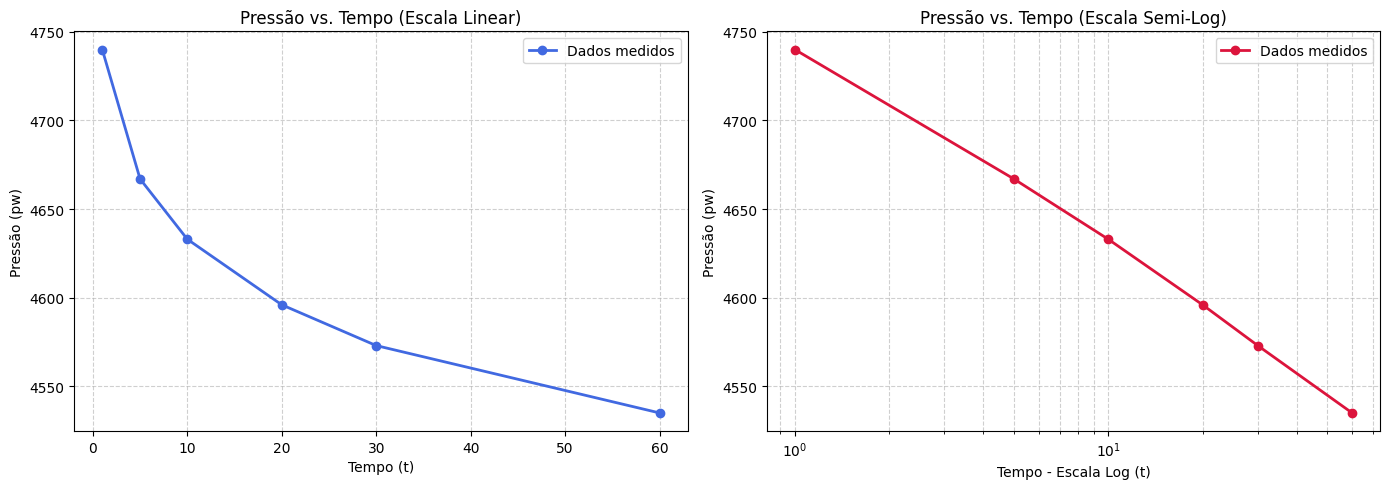

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Criando a figura com dois subplots para melhor análise
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfico em escala linear
ax1.plot(tempo, pressao, marker='o', color='royalblue', linestyle='-', linewidth=2, label='Dados medidos')
ax1.set_title('Pressão vs. Tempo (Escala Linear)')
ax1.set_xlabel('Tempo (t)')
ax1.set_ylabel('Pressão (pw)')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# 2. Gráfico em escala semi-log (tempo em log)
ax2.plot(tempo, pressao, marker='o', color='crimson', linestyle='-', linewidth=2, label='Dados medidos')
ax2.set_xscale('log')
ax2.set_title('Pressão vs. Tempo (Escala Semi-Log)')
ax2.set_xlabel('Tempo - Escala Log (t)')
ax2.set_ylabel('Pressão (pw)')
ax2.grid(True, which="both", linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

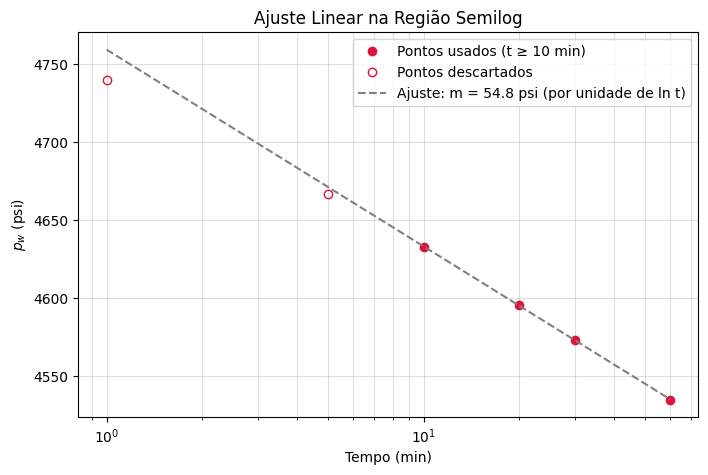

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Convertendo as listas para arrays numpy para permitir o uso de máscaras booleanas
t = np.array(tempo)
pw = np.array(pressao)

# Aplicando a máscara para t >= 10
mask = t >= 10
coef = np.polyfit(np.log(t[mask]), pw[mask], 1)
t_fit = np.linspace(1, 60, 100)

# Criando a figura do gráfico semi-log
plt.figure(figsize=(8, 5))

# Plotando os pontos utilizados no ajuste
plt.semilogx(t[mask], pw[mask], 'o', color='crimson', label='Pontos usados (t ≥ 10 min)')

# Plotando os pontos descartados do ajuste
plt.semilogx(t[~mask], pw[~mask], 'o', mfc='none', color='crimson', label='Pontos descartados')

# Plotando a reta ajustada
plt.semilogx(t_fit, np.polyval(coef, np.log(t_fit)), '--', color='gray',
             label=f'Ajuste: m = {-coef[0]:.1f} psi (por unidade de ln t)')

plt.xlabel('Tempo (min)')
plt.ylabel('$p_w$ (psi)')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.title('Ajuste Linear na Região Semilog')
plt.show()